<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Compare profiles on a declared basis

**Can a capture use more CPU in total but less CPU per completed operation?**
We will decode two authored pprof files, identify CPU values from each file's metadata,
and compare leaf-attributed CPU on a declared basis. A full outer difference retains
leaf categories observed on only one side. Unknown symbols and a broken profile stay
visible instead of silently shrinking the denominator.

These are synthetic profiles and authored workload counts, not benchmark measurements.
The arithmetic demonstrates how denominators change a comparison; it does not establish
a performance regression or improvement. Real comparisons require comparable workloads,
capture settings, environments and repeated measurements.

## Choose the comparison basis

`PER_OPERATION=True` divides each capture's attributed CPU by its separately supplied
completed-operation count. The experiment changes it to `False` to compare captured
CPU totals. These answer different questions. The raw profiles and workload counts
stay fixed. Restart and run all after editing the boolean.

In [1]:
PER_OPERATION = True

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
import haybarn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from notebook_support import finish, prose, theme

if type(PER_OPERATION) is not bool:
    raise ValueError("PER_OPERATION must be True or False.")
parts = delta = totals = checks = pd.DataFrame()
unit = "CPU milliseconds per completed operation" if PER_OPERATION else "Captured CPU milliseconds"
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-pprof/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-pprof/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-pprof/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-pprof/notebooks/pyproject.toml.

## Attach the pinned native release

The literal `github-auto` location downloads and verifies v0.4.0 for this platform,
then caches it. No Rust toolchain, local worker build or profiling daemon is required.
All profile bytes are committed, deterministic fixtures. The worker only reads them.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'pprof' (TYPE vgi,LOCATION 'github-auto://Query-farm/vgi-pprof@v0.4.0');

,Success


## Keep the file inventory and workload denominator explicit

The candidate capture lasts two seconds and represents 200 completed operations;
the baseline lasts one second and represents 100. Duration comes from the profile.
Completed operations are separately authored workload metadata and are not inferred
from sample count or duration. A third file is intentionally truncated to demonstrate
the worker's per-file error channel. It is a diagnostic fixture, not a third cohort.

`meta()` returns one error row for the broken file while preserving successful files.
That failure is unknown profile data, not zero CPU. Check it before aggregating.

In [4]:
%%sql
CREATE TABLE manifest AS
SELECT * FROM (VALUES
 ('fixtures/baseline.pb.gz','baseline',100),
 ('fixtures/candidate.pb.gz','candidate',200),
 ('fixtures/broken.pb.gz','diagnostic',NULL)
) t(file,cohort,completed_operations);
CREATE TABLE profile_meta AS SELECT * FROM pprof.main.meta('fixtures/*.pb.gz');
CREATE TABLE raw_stacks AS SELECT * FROM pprof.main.stacks('fixtures/*.pb.gz');
SELECT m.cohort,m.completed_operations,p.duration_nanos/1e9 AS duration_seconds,
 p.sample_types,p.error FROM manifest m LEFT JOIN profile_meta p USING(file)
ORDER BY m.cohort;

,cohort,completed_operations,duration_seconds,sample_types,error
0,baseline,100,1.0,"[{'type': 'samples', 'unit': 'count'}, {'type'...",None
1,candidate,200,2.0,"[{'type': 'cpu', 'unit': 'nanoseconds'}, {'typ...",None
2,diagnostic,<NA>,NaN,<NA>,gzip decompression failed: incomplete deflate ...


## Select the CPU slot by type and unit, not a memorized index

Both profiles have `cpu/nanoseconds` and `samples/count`, but their slot order is
deliberately reversed. DuckDB list indexing is one based. Expand `sample_types` with
ordinality and use that position to select the matching `value` element for each file.
The metadata checks require exactly one CPU/nanoseconds slot per valid profile.

The values are already attributed CPU nanoseconds. Do not multiply by the sampling
period again. Likewise, the sample-count slot is not a completed-operation count.

In [5]:
%%sql
CREATE TABLE cpu_slots AS
SELECT p.file,t.ordinality AS value_index,p.duration_nanos
FROM profile_meta p,unnest(p.sample_types) WITH ORDINALITY AS t(sample_type,ordinality)
WHERE p.error IS NULL AND t.sample_type.type='cpu' AND t.sample_type.unit='nanoseconds';
SELECT m.cohort,c.value_index FROM cpu_slots c JOIN manifest m USING(file) ORDER BY cohort;
CREATE TABLE sample_cpu AS
SELECT m.cohort,m.completed_operations,s.file,s.sample_id,s.value[c.value_index] AS cpu_ns,
 s.frame[1].function AS leaf_function,s.frame[1].filename AS leaf_file,
 s.frame[1].address AS leaf_address,len(s.frame) AS frame_count
FROM raw_stacks s JOIN cpu_slots c USING(file) JOIN manifest m USING(file)
WHERE s.error IS NULL;
SELECT cohort,sample_id,cpu_ns,leaf_function,leaf_file,leaf_address,frame_count
FROM sample_cpu ORDER BY cohort,sample_id;

,cohort,sample_id,cpu_ns,leaf_function,leaf_file,leaf_address,frame_count
0,baseline,1,70000000,parse,synthetic.go,4194336,2
1,baseline,2,30000000,serialize,synthetic.go,4194352,2
2,baseline,3,20000000,legacy,synthetic.go,4194368,2
3,baseline,4,10000000,None,None,4194400,2
4,candidate,1,90000000,parse,synthetic.go,4194336,2
5,candidate,2,70000000,serialize,synthetic.go,4194352,2
6,candidate,3,20000000,new_cache,synthetic.go,4194384,2
7,candidate,4,10000000,None,None,4194400,2


## Attribute each sample once to its leaf

Frames are leaf first. Grouping `frame[1]` attributes every sample once. Expanding
every stack frame and summing would instead produce inclusive attribution and count
the same sample at multiple levels; those inclusive rows cannot be summed as a CPU total.

An address-only leaf remains an explicit unknown-symbol bucket. It is not a function
named “unknown,” and equal raw addresses across different builds do not prove identical
code. The known categories use both function name and source filename. A real symbol
identity strategy may need build and language-specific information too.

In [6]:
%%sql
CREATE TABLE leaf_cpu AS
SELECT cohort,leaf_function,leaf_file,
 coalesce(leaf_function,'[unsymbolized]') AS leaf_label,
 sum(cpu_ns) AS cpu_ns,first(completed_operations) AS completed_operations,
 sum(cpu_ns)/1e6 AS total_cpu_ms,
 sum(cpu_ns)/1e6/first(completed_operations) AS cpu_ms_per_operation
FROM sample_cpu GROUP BY cohort,leaf_function,leaf_file;
CREATE TABLE comparison_values AS
SELECT *,CASE WHEN {{ PER_OPERATION }} THEN cpu_ms_per_operation ELSE total_cpu_ms END AS selected_value
FROM leaf_cpu;
SELECT cohort,sum(total_cpu_ms) AS total_cpu_ms,sum(cpu_ms_per_operation) AS cpu_ms_per_operation,
 first(completed_operations) AS completed_operations
FROM leaf_cpu GROUP BY cohort ORDER BY cohort;

,cohort,total_cpu_ms,cpu_ms_per_operation,completed_operations
0,baseline,130.0,1.30,100
1,candidate,190.0,0.95,200


In [7]:
%%sql parts <<
SELECT cohort,leaf_label,selected_value FROM comparison_values ORDER BY cohort,leaf_label;

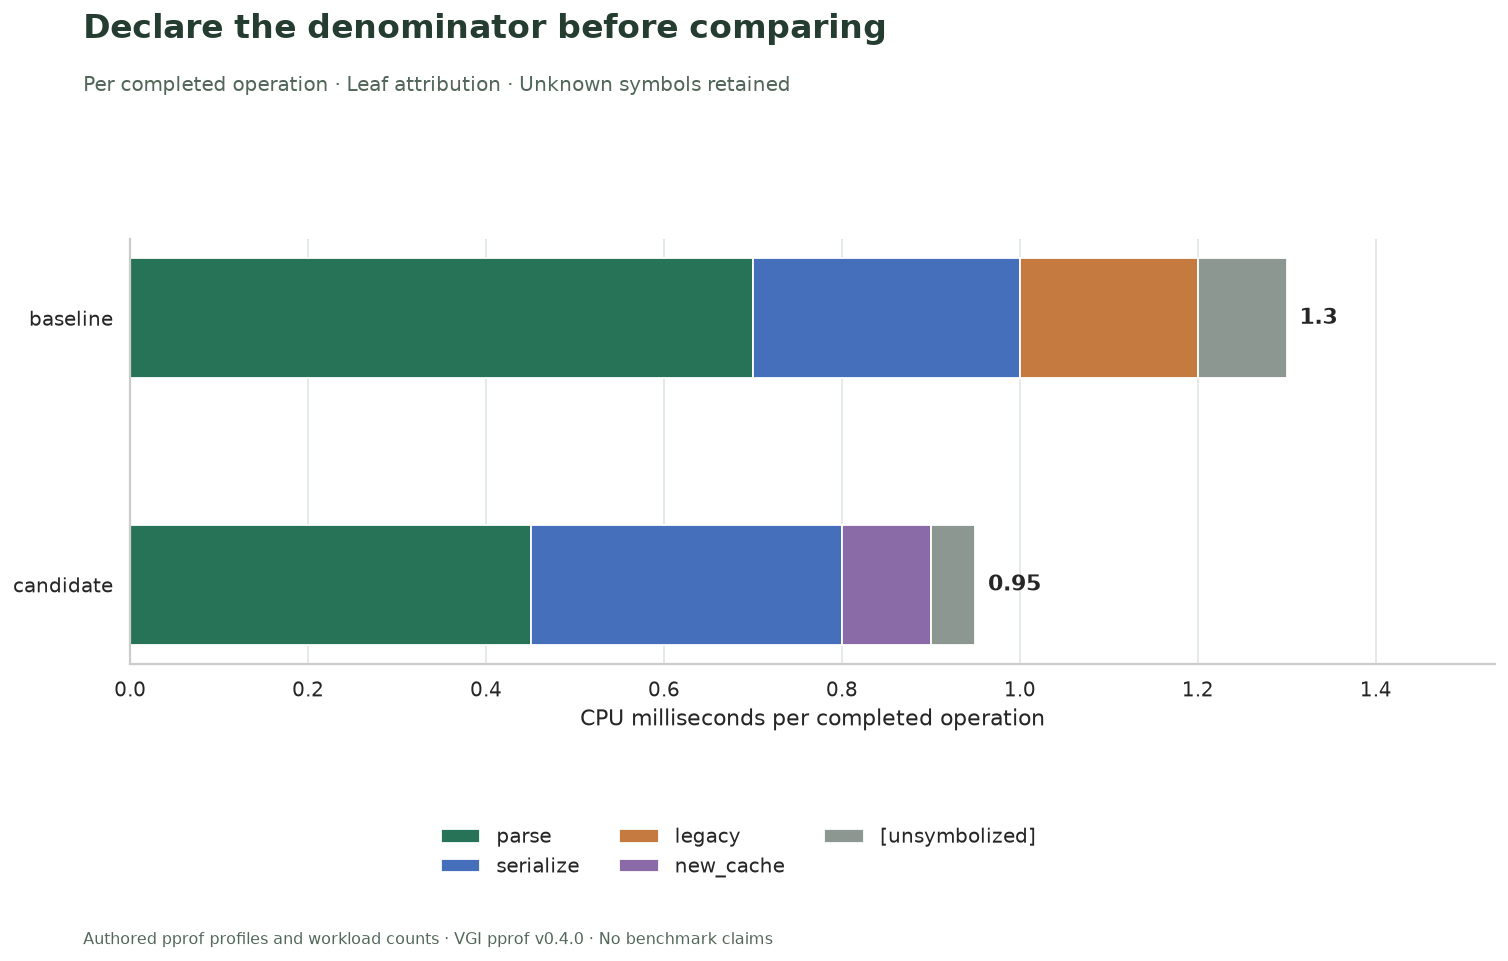

On the selected basis, baseline is **1.3** and candidate is **0.95** (cpu milliseconds per completed operation). The difference is **-0.35**. These stacked parts partition the profile's CPU values; they do not stack inclusive call-tree totals.

In [8]:
colors = {
    "parse": "#267358",
    "serialize": "#456fba",
    "legacy": "#c57b40",
    "new_cache": "#8b6aa8",
    "[unsymbolized]": "#8b9790",
}
wide = (
    parts.pivot(index="cohort", columns="leaf_label", values="selected_value")
    .fillna(0)
    .reindex(["baseline", "candidate"])
)
fig, ax = plt.subplots(figsize=(12, 7.5))
left = np.zeros(2)
for label, color in colors.items():
    values = wide[label].to_numpy()
    ax.barh(wide.index, values, left=left, color=color, height=0.45, label=label)
    left += values
for y, total in enumerate(left):
    ax.annotate(
        f"{total:.3g}",
        (total, y),
        xytext=(7, 0),
        textcoords="offset points",
        va="center",
        fontsize=12,
        weight="bold",
    )
ax.invert_yaxis()
ax.set_xlim(0, float(left.max()) * 1.18)
ax.set_xlabel(unit)
ax.grid(axis="y", visible=False)
fig.legend(loc="lower center", bbox_to_anchor=(0.5, 0.075), ncol=3, frameon=False)
finish(
    fig,
    "Declare the denominator before comparing",
    f"{'Per completed operation' if PER_OPERATION else 'Whole capture totals'} · Leaf attribution · Unknown symbols retained",
    "01_cpu_comparison.png",
    bottom=0.22,
)
prose(
    f"On the selected basis, baseline is **{left[0]:.3g}** and candidate is **{left[1]:.3g}** "
    f"({unit.lower()}). The difference is **{left[1] - left[0]:+.3g}**. "
    "These stacked parts partition the profile's CPU values; they do not stack inclusive call-tree totals."
)

## Use a full outer difference to retain both sides

`legacy` has observed leaf samples only in the baseline; `new_cache` only in the
candidate. A candidate-only left join would hide the baseline-only category. Use a
full outer join on the known name/file pair, with explicit NULL-safe matching for
the aggregate unsymbolized bucket.

Zero filling here means no observed leaf sample for that category in a **successfully
decoded capture**. It is not proof that the function was absent from the executable,
and it is never used for the failed profile. Unknown-symbol differences compare
aggregate unknown CPU, not matching symbol identities.

In [9]:
%%sql
CREATE TABLE leaf_diff AS
SELECT coalesce(b.leaf_label,c.leaf_label) AS leaf_label,
 coalesce(b.leaf_file,c.leaf_file) AS leaf_file,
 coalesce(b.selected_value,0) AS baseline_value,coalesce(c.selected_value,0) AS candidate_value,
 coalesce(c.selected_value,0)-coalesce(b.selected_value,0) AS delta,
 b.cohort IS NOT NULL AS observed_in_baseline,c.cohort IS NOT NULL AS observed_in_candidate
FROM (SELECT * FROM comparison_values WHERE cohort='baseline') b
FULL OUTER JOIN (SELECT * FROM comparison_values WHERE cohort='candidate') c
ON b.leaf_function IS NOT DISTINCT FROM c.leaf_function
AND b.leaf_file IS NOT DISTINCT FROM c.leaf_file;
SELECT * FROM leaf_diff ORDER BY delta,leaf_label;

,leaf_label,leaf_file,baseline_value,candidate_value,delta,observed_in_baseline,observed_in_candidate
0,parse,synthetic.go,0.7,0.45,-0.25,True,True
1,legacy,synthetic.go,0.2,0.00,-0.20,True,False
2,[unsymbolized],None,0.1,0.05,-0.05,True,True
3,serialize,synthetic.go,0.3,0.35,0.05,True,True
4,new_cache,synthetic.go,0.0,0.10,0.10,False,True


In [10]:
%%sql delta <<
SELECT * FROM leaf_diff ORDER BY delta,leaf_label;

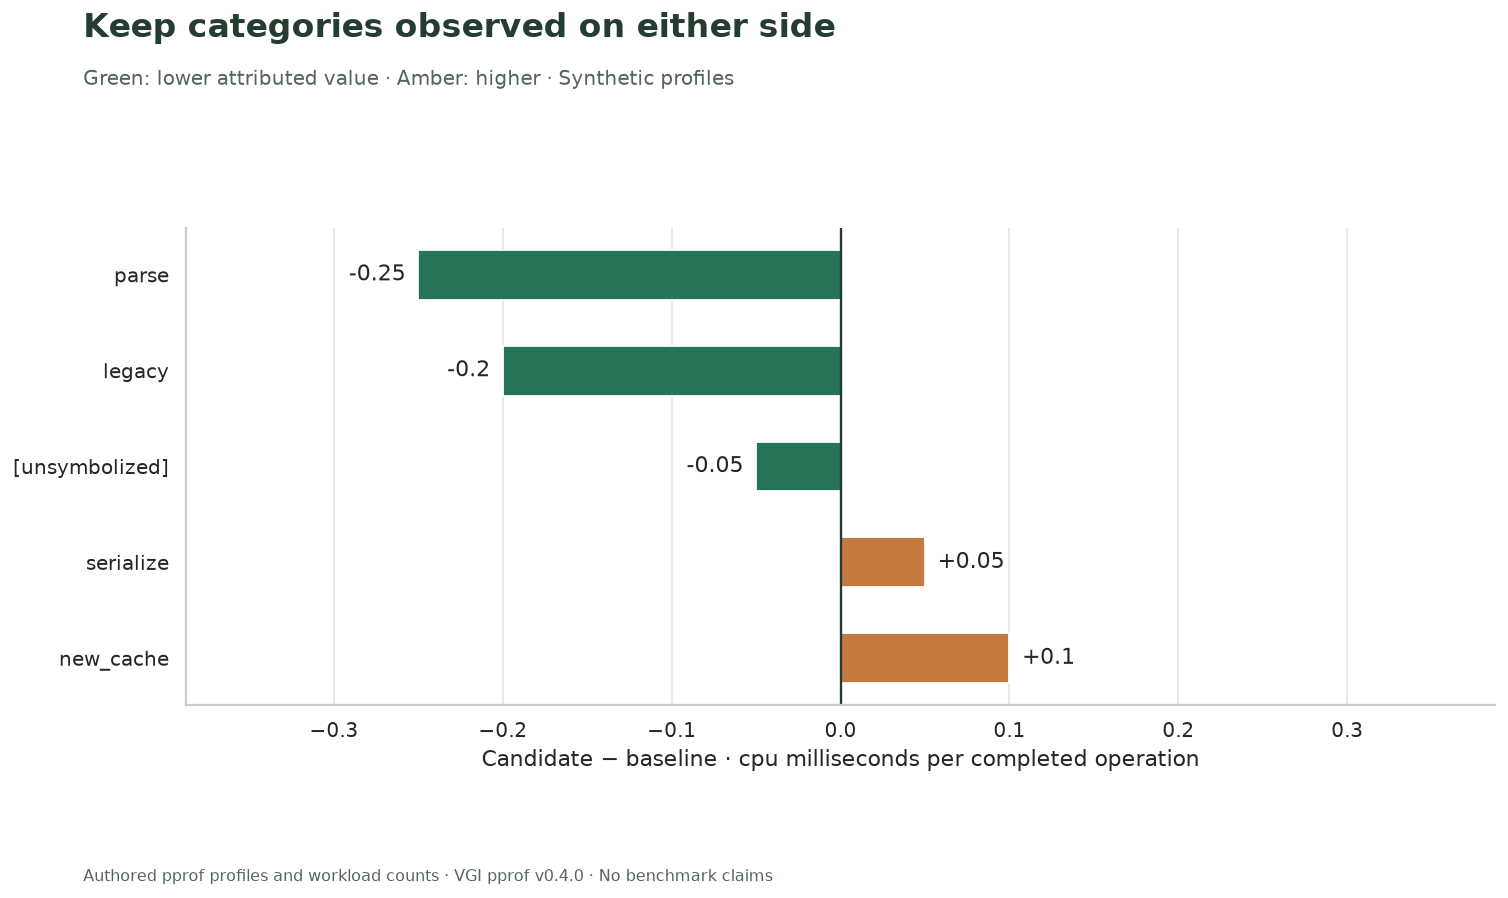

The leaf differences sum to **-0.35** on this basis. The baseline-only legacy category remains visible with a negative contribution, while new_cache has a positive contribution. Neither sign alone establishes a real performance effect.

,leaf_label,baseline_value,candidate_value,observed_in_baseline,observed_in_candidate
0,parse,0.7,0.45,True,True
1,legacy,0.2,0.00,True,False
2,[unsymbolized],0.1,0.05,True,True
3,serialize,0.3,0.35,True,True
4,new_cache,0.0,0.10,False,True


In [11]:
fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(
    delta.leaf_label,
    delta.delta,
    color=["#267358" if x < 0 else "#c57b40" for x in delta.delta],
    height=0.52,
)
span = max(float(delta.delta.abs().max()), 0.001)
for bar, value in zip(bars, delta.delta):
    ax.annotate(
        f"{value:+.3g}",
        (value, bar.get_y() + bar.get_height() / 2),
        xytext=(7 if value >= 0 else -7, 0),
        textcoords="offset points",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=12,
    )
ax.axvline(0, color="#253d31", linewidth=1.3)
ax.set_xlim(-span * 1.55, span * 1.55)
ax.invert_yaxis()
ax.set_xlabel(f"Candidate − baseline · {unit.lower()}")
ax.grid(axis="y", visible=False)
finish(
    fig,
    "Keep categories observed on either side",
    "Green: lower attributed value · Amber: higher · Synthetic profiles",
    "02_leaf_difference.png",
    bottom=0.12,
)
prose(
    f"The leaf differences sum to **{float(delta.delta.sum()):+.3g}** on this basis. "
    "The baseline-only legacy category remains visible with a negative contribution, while new_cache has a positive contribution. "
    "Neither sign alone establishes a real performance effect."
)
display(
    delta[
        [
            "leaf_label",
            "baseline_value",
            "candidate_value",
            "observed_in_baseline",
            "observed_in_candidate",
        ]
    ]
)

## Preserve the build context for unsymbolized addresses

For symbolization, raw profile IDs join **within each file**. Joining only on numeric
IDs would cross the two captures, whose IDs intentionally overlap. Keep the mapping's
build ID and binary-relative offset; a matching binary and a symbolization worker
would be needed to identify the function. These fixtures contain no such binary.

In [12]:
%%sql
CREATE TABLE profile_samples AS SELECT * FROM pprof.main.samples('fixtures/*.pb.gz');
CREATE TABLE profile_locations AS SELECT * FROM pprof.main.locations('fixtures/*.pb.gz');
CREATE TABLE profile_mappings AS SELECT * FROM pprof.main.mappings('fixtures/*.pb.gz');
CREATE TABLE unknown_addresses AS
SELECT c.cohort,c.sample_id,m.build_id,m.filename AS binary_path,
 l.address,l.address-m.memory_start+m.file_offset AS binary_offset,c.cpu_ns
FROM sample_cpu c JOIN profile_samples s ON c.file=s.file AND c.sample_id=s.sample_id
JOIN profile_locations l ON s.file=l.file AND s.location_ids[1]=l.location_id
JOIN profile_mappings m ON l.file=m.file AND l.mapping_id=m.mapping_id
WHERE c.leaf_function IS NULL AND s.error IS NULL AND l.error IS NULL AND m.error IS NULL;
SELECT * FROM unknown_addresses ORDER BY cohort;

,cohort,sample_id,build_id,binary_path,address,binary_offset,cpu_ns
0,baseline,4,baseline-build,/synthetic/app,4194400,96,10000000
1,candidate,4,candidate-build,/synthetic/app,4194400,96,10000000


## Check coverage, units and accounting

These checks include known fixture totals, reversed metric slots, failed-file retention,
and reconciliation of every leaf delta with the selected capture difference. The
operation counts are fixture inputs, not values validated by the profiler.

In [13]:
%%sql checks <<
SELECT 'Every manifest file has one metadata row' AS check_name,
 (SELECT count(*)=3 AND count(DISTINCT file)=3 FROM profile_meta) AS passed
UNION ALL SELECT 'Broken profile stays an error rather than zero CPU',
 (SELECT error IS NOT NULL AND value IS NULL FROM raw_stacks WHERE file='fixtures/broken.pb.gz')
UNION ALL SELECT 'Two valid profiles each have exactly one CPU slot',
 (SELECT count(*)=2 AND count(DISTINCT file)=2 FROM cpu_slots)
UNION ALL SELECT 'The fixture CPU slot order differs between captures',
 (SELECT value_index=2 FROM cpu_slots WHERE file='fixtures/baseline.pb.gz')
 AND (SELECT value_index=1 FROM cpu_slots WHERE file='fixtures/candidate.pb.gz')
UNION ALL SELECT 'Decoded CPU totals match authored values',
 (SELECT sum(cpu_ns)=130000000 FROM sample_cpu WHERE cohort='baseline')
 AND (SELECT sum(cpu_ns)=190000000 FROM sample_cpu WHERE cohort='candidate')
UNION ALL SELECT 'Workload denominator is positive for every valid sample',
 NOT EXISTS(SELECT 1 FROM sample_cpu WHERE completed_operations IS NULL OR completed_operations<=0)
UNION ALL SELECT 'Four samples per capture retain their IDs without cross-file multiplication',
 (SELECT count(*)=8 FROM sample_cpu) AND NOT EXISTS(SELECT cohort,sample_id FROM sample_cpu GROUP BY ALL HAVING count(*)<>1)
UNION ALL SELECT 'Two frames per sample would double inclusive summed attribution',
 (SELECT sum(cpu_ns*frame_count)=2*sum(cpu_ns) FROM sample_cpu)
UNION ALL SELECT 'Both one-sided categories survive the full outer join',
 (SELECT observed_in_baseline AND NOT observed_in_candidate FROM leaf_diff WHERE leaf_label='legacy')
 AND (SELECT NOT observed_in_baseline AND observed_in_candidate FROM leaf_diff WHERE leaf_label='new_cache')
UNION ALL SELECT 'Unsymbolized CPU remains in both profile totals',
 (SELECT count(*)=2 AND sum(cpu_ns)=20000000 FROM sample_cpu WHERE leaf_function IS NULL)
UNION ALL SELECT 'File-scoped symbolization joins retain both build identities',
 (SELECT count(*)=2 AND count(DISTINCT build_id)=2 AND bool_and(binary_offset=96) FROM unknown_addresses)
UNION ALL SELECT 'Leaf differences reconcile to the chosen total difference',
 abs((SELECT sum(delta) FROM leaf_diff)-
 ((SELECT sum(selected_value) FROM comparison_values WHERE cohort='candidate')-
 (SELECT sum(selected_value) FROM comparison_values WHERE cohort='baseline')))<1e-9;

In [14]:
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
assert abs(float(delta.delta.sum()) - (float(left[1]) - float(left[0]))) < 1e-9
prose(
    f"**{len(checks)} SQL checks plus chart/difference reconciliation passed.** Raw values, unit selection and cohort coverage are explicit."
)

**12 SQL checks plus chart/difference reconciliation passed.** Raw values, unit selection and cohort coverage are explicit.

## Experiment · switch from per-operation values to capture totals

Change only `PER_OPERATION` from **True to False**, restart, and run all. Predict
which leaf deltas change sign and what happens to the capture-level difference.
Metric slots, raw CPU nanoseconds, operation counts and the failed-profile audit
should remain unchanged. Read the new units on both charts before comparing numbers.

The experiment changes the question, not the measurement. For real profiling work,
verify workload comparability and sampling uncertainty before drawing conclusions.
Reset `PER_OPERATION=True` for the saved default.

In [15]:
con.close()
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)